In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
#%pip install pandas numpy matplotlib seaborn scikit-learn

In [8]:
data = pd.read_csv("Student_Performance.csv")
data


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,...,3,2,3,3,3,5,5,8,9,9
395,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6


In [9]:
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [10]:
data.tail()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,...,3,2,3,3,3,5,5,8,9,9
395,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
396,MS,M,19,R,GT3,T,1,1,other,services,...,4,3,2,1,3,5,0,6,5,0


In [11]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      397 non-null    str  
 1   sex         397 non-null    str  
 2   age         397 non-null    int64
 3   address     397 non-null    str  
 4   famsize     397 non-null    str  
 5   Pstatus     397 non-null    str  
 6   Medu        397 non-null    int64
 7   Fedu        397 non-null    int64
 8   Mjob        397 non-null    str  
 9   Fjob        397 non-null    str  
 10  reason      397 non-null    str  
 11  guardian    397 non-null    str  
 12  traveltime  397 non-null    int64
 13  studytime   397 non-null    int64
 14  failures    397 non-null    int64
 15  schoolsup   397 non-null    str  
 16  famsup      397 non-null    str  
 17  paid        397 non-null    str  
 18  activities  397 non-null    str  
 19  nursery     397 non-null    str  
 20  higher      397 non-null    str  
 21  inte

In [12]:
data.shape

(397, 33)

In [13]:
data.size

13101

In [15]:
data.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000,397.000000
mean,16.705290,2.748111,2.521411,1.450882,2.032746,0.335013,3.944584,3.234257,3.108312,1.478589,2.289673,3.556675,5.695214,10.881612,10.687657,10.377834
std,1.279716,1.097301,1.090672,0.696840,0.838731,0.742714,0.894400,0.996476,1.112762,0.889143,1.286770,1.388967,7.988015,3.333120,3.770322,4.604928
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [17]:
pd.set_option('display.max_rows',None)
data

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,12,12,11
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,6,6,5,6
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,16,18,19
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,14,15,15


In [18]:
data.columns.tolist()

['school',
 'sex',
 'age',
 'address',
 'famsize',
 'Pstatus',
 'Medu',
 'Fedu',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'traveltime',
 'studytime',
 'failures',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic',
 'famrel',
 'freetime',
 'goout',
 'Dalc',
 'Walc',
 'health',
 'absences',
 'G1',
 'G2',
 'G3']

In [19]:
data.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [20]:
data.duplicated().sum()

np.int64(2)

In [21]:
data = data.drop_duplicates()

print("Duplicate rows:", data.duplicated().sum())
print("Updated dataset shape:", data.shape)

Duplicate rows: 0
Updated dataset shape: (395, 33)


In [23]:
X = data[["G1", "G2"]]
y = data["G3"]

print("X and y created successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

X and y created successfully!
X shape: (395, 2)
y shape: (395,)


In [24]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (316, 2)
Testing data: (79, 2)


In [26]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [27]:
y_pred = model.predict(X_test)

print("Actual Grades:")
print(y_test.head().to_list())

print("\nPredicted Grades:")
print(y_pred[:5])

Actual Grades:
[10, 12, 5, 10, 9]

Predicted Grades:
[ 7.21354671 12.16512128  3.41829665  8.20673293  8.36987121]


In [28]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("R2 Score:", r2)
print("R2 Score Percentage:", round(r2 * 100, 2), "%")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))

R2 Score: 0.7945936216805897
R2 Score Percentage: 79.46 %
Mean Absolute Error: 1.26
Mean Squared Error: 4.21


In [29]:
print("R2 Score:", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))

R2 Score: 0.795
MAE: 1.26


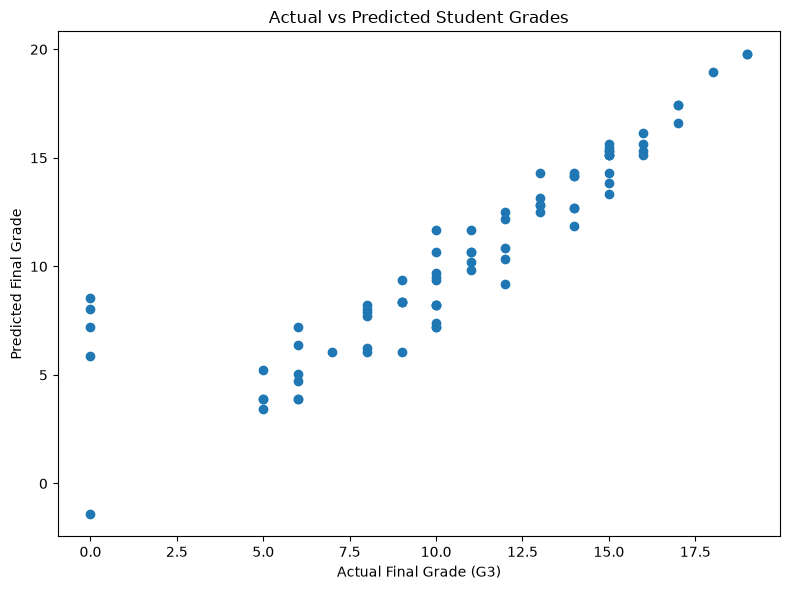

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Grades")
plt.tight_layout()
plt.show()

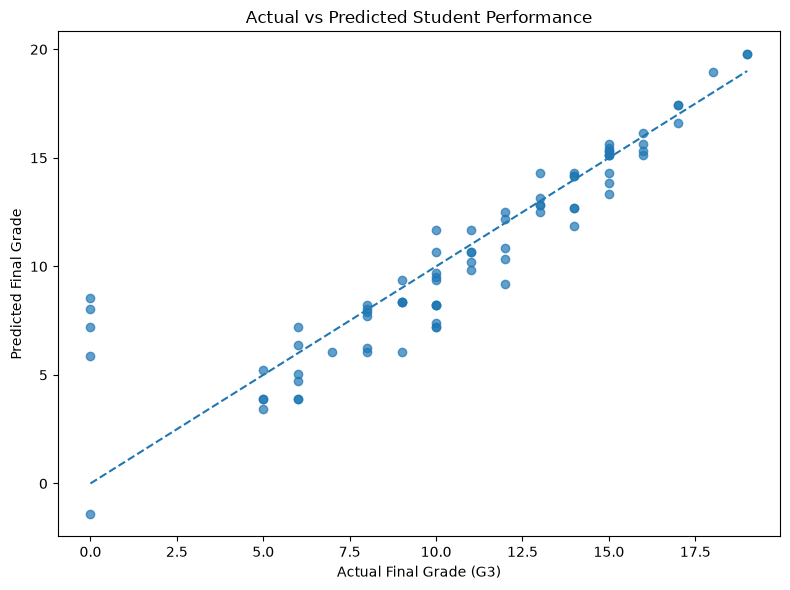

In [31]:
#import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Performance")
plt.tight_layout()
plt.show()

In [32]:
new_student = pd.DataFrame({
    "G1": [12],
    "G2": [14]
})

predicted_grade = model.predict(new_student)

print("Predicted Final Grade (G3):", round(predicted_grade[0], 2))

Predicted Final Grade (G3): 13.83


In [33]:
results = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": y_pred
})

results["Predicted Grade"] = results["Predicted Grade"].round(2)

display(results.head(10))

,Actual Grade,Predicted Grade
0,10,7.21
1,12,12.17
2,5,3.42
3,10,8.21
4,9,8.37
5,13,12.83
6,18,18.94
7,6,6.38
8,0,7.21
9,14,12.67


In [34]:
import os

os.makedirs("../outputs", exist_ok=True)

results.to_csv("../outputs/student_performance_predictions.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [35]:
metrics = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE"],
    "Value": [
        r2_score(y_test, y_pred),
        mean_absolute_error(y_test, y_pred),
        mean_squared_error(y_test, y_pred)
    ]
})

metrics.to_csv("../outputs/model_evaluation_metrics.csv", index=False)

display(metrics)

,Metric,Value
0,R2 Score,0.794594
1,MAE,1.262231
2,MSE,4.211867
